# 규칙이 관중을 불렀는가?
이규돈 · 데이터과학및분석소개

2010–2025년 MLB 30개 구단의 경기당 관중을 세 기준으로 비교한다. 첫 셀부터 순서대로 실행하면 표와 그래프가 생성된다. 2025년판 Teams.csv를 노트북 옆에 두거나 인터넷에 연결하면 두 번째 코드 셀이 고정 버전의 CSV를 읽는다. 그림 파일은 output/에 저장된다.

[SABR 데이터 안내](https://sabr.org/lahman-database/) · [프로젝트 설명](https://dlrbehs.github.io/mlb.html)
패키지 버전은 requirements.txt로 고정합니다. 입력 파일의 SHA-256이 다르면 분석을 중단합니다. 마지막 셀은 generated/에 검토표·리그 집계·핵심 수치 JSON을 자동 저장합니다. p값과 신뢰구간은 구단간 독립성 등 확률모형 가정에 조건부인 보조 결과입니다.


In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson

available = {font.name for font in font_manager.fontManager.ttflist}
for family in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
    if family in available:
        plt.rc('font', family=family)
        break
mpl.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120
os.makedirs('output', exist_ok=True)

In [2]:
import hashlib
from io import BytesIO
from urllib.request import urlopen

csv_url = 'https://raw.githubusercontent.com/corbtastik/lahman-baseball-db/b5e7327707fff91ff3bdcbe1f6892c8c5015cf1d/Teams.csv'
EXPECTED_SHA256 = '0e7afdd8b837d0edaca770a28817eec6613bd8255979c1be6e3f5827f4b88fd6'
csv_path = Path('Teams.csv')
if csv_path.exists():
    data = csv_path.read_bytes()
else:
    with urlopen(csv_url, timeout=30) as response:
        data = response.read()
source_sha256 = hashlib.sha256(data).hexdigest()
if source_sha256 != EXPECTED_SHA256:
    raise ValueError('Teams.csv SHA-256 불일치: 로컬 파일을 확인하세요. 기존 파일을 보관한 뒤 고정 버전으로 재실행하세요. 새 시즌 자료로 갱신할 때는 출처와 기준값을 별도로 검토해야 합니다.')
teams = pd.read_csv(BytesIO(data), encoding='utf-8-sig')
print('원자료 행과 열', teams.shape)
print('수록 연도', teams.yearID.min(), '–', teams.yearID.max())
print('CSV SHA-256 검증 통과', source_sha256)


원자료 행과 열 (3614, 48)
수록 연도 1871 – 2025
CSV SHA-256 검증 통과 0e7afdd8b837d0edaca770a28817eec6613bd8255979c1be6e3f5827f4b88fd6


In [3]:
need = ['yearID','lgID','teamID','franchID','name','G','Ghome','W','L','park','attendance']
teams = teams.loc[teams.yearID.between(2010, 2025) & teams.lgID.isin(['AL', 'NL']), need].copy()
print('분석 표본 행과 열 (파생 전)', teams.shape)
print('결측값 수', teams.isna().sum().sum())
print('2020년 관중이 0인 구단', teams.loc[(teams.yearID == 2020) & (teams.attendance == 0), 'franchID'].nunique())
assert not teams.duplicated(['yearID', 'franchID']).any()
assert (teams.Ghome > 0).all()
assert teams.groupby('yearID').franchID.nunique().eq(30).all()
teams['att_per_game'] = teams.attendance / teams.Ghome
teams.tail()

분석 표본 행과 열 (파생 전) (480, 11)
결측값 수 0
2020년 관중이 0인 구단 30
Out[3]: 
      yearID lgID teamID  ...                 park attendance  att_per_game
3609    2025   NL    SLN  ...    Busch Stadium III  2250007.0  27777.864198
3610    2025   AL    TBA  ...  Steinbrenner Field    786750.0   9712.962963
3611    2025   AL    TEX  ...     Globe Life Field  2397071.0  29593.469136
3612    2025   AL    TOR  ...        Rogers Centre  2849935.0  35184.382716
3613    2025   NL    WAS  ...       Nationals Park  1916768.0  23663.802469

[5 rows x 12 columns]


In [4]:
def match_counts(start, end, key):
    by_year = teams.loc[teams.yearID.isin([start, end])].pivot(
        index=key, columns='yearID', values='att_per_game')
    return len(by_year[[start, end]].dropna())

for start, end in [(2019, 2023), (2022, 2023), (2022, 2025)]:
    print(f"{start}→{end}  teamID {match_counts(start,end,'teamID')}개, "
          f"franchID {match_counts(start,end,'franchID')}개")
print(teams.loc[(teams.franchID == 'OAK') & teams.yearID.isin([2022, 2025]),
                ['yearID','teamID','franchID']].to_string(index=False))

2019→2023  teamID 30개, franchID 30개
2022→2023  teamID 30개, franchID 30개
2022→2025  teamID 29개, franchID 30개
 yearID teamID franchID
   2022    OAK      OAK
   2025    ATH      OAK


In [5]:
summary = teams.groupby('yearID').agg(
    팀수=('teamID', 'count'),
    총관중=('attendance', 'sum'),
    총홈경기=('Ghome', 'sum'),
)
summary['경기당관중'] = round(summary['총관중'] / summary['총홈경기'], 3)
summary

Out[5]: 
        팀수         총관중    총홈경기      경기당관중
yearID                                   
2010    30  73053807.0  2430.0  30063.295
2011    30  73425667.0  2429.0  30228.764
2012    30  74859268.0  2430.0  30806.283
2013    30  74026895.0  2431.0  30451.211
2014    30  73739622.0  2430.0  30345.523
2015    30  73719330.0  2429.0  30349.662
2016    30  73159044.0  2428.0  30131.402
2017    30  72670425.0  2430.0  29905.525
2018    30  69671272.0  2431.0  28659.511
2019    30  68494865.0  2429.0  28198.792
2020    30         0.0   898.0      0.000
2021    30  45304709.0  2429.0  18651.589
2022    30  64556658.0  2430.0  26566.526
2023    30  70747365.0  2430.0  29114.142
2024    30  71348405.0  2429.0  29373.571
2025    30  71409421.0  2430.0  29386.593


In [6]:
g22 = summary.loc[2022, '총관중']
g23 =summary.loc[2023, '총관중']

print("MLB 공식 발표 확인")
print((g23 - g22) / g22 * 100, "%")
totals = teams.pivot(index='franchID', columns='yearID', values='attendance')
print('총관중이 증가한 구단', int((totals[2023] > totals[2022]).sum()), '/ 30')

MLB 공식 발표 확인
9.589571690653504 %
총관중이 증가한 구단 26 / 30


In [7]:
for y in [2019, 2022, 2023]:
    v = summary.loc[y, '경기당관중']
    base = summary.loc[2019, '경기당관중']
    print(y, ": 경기당관중",  v,"명","(2019 대비", round((v-base) / base * 100, 2), "%)")
change = summary.loc[2019, '경기당관중'] / summary.loc[2012, '경기당관중'] - 1
print(f'2012→2019 경기당 관중 변화율 {change:.2%}')

2019 : 경기당관중 28198.792 명 (2019 대비 0.0 %)
2022 : 경기당관중 26566.526 명 (2019 대비 -5.79 %)
2023 : 경기당관중 29114.142 명 (2019 대비 3.25 %)
2012→2019 경기당 관중 변화율 -8.46%


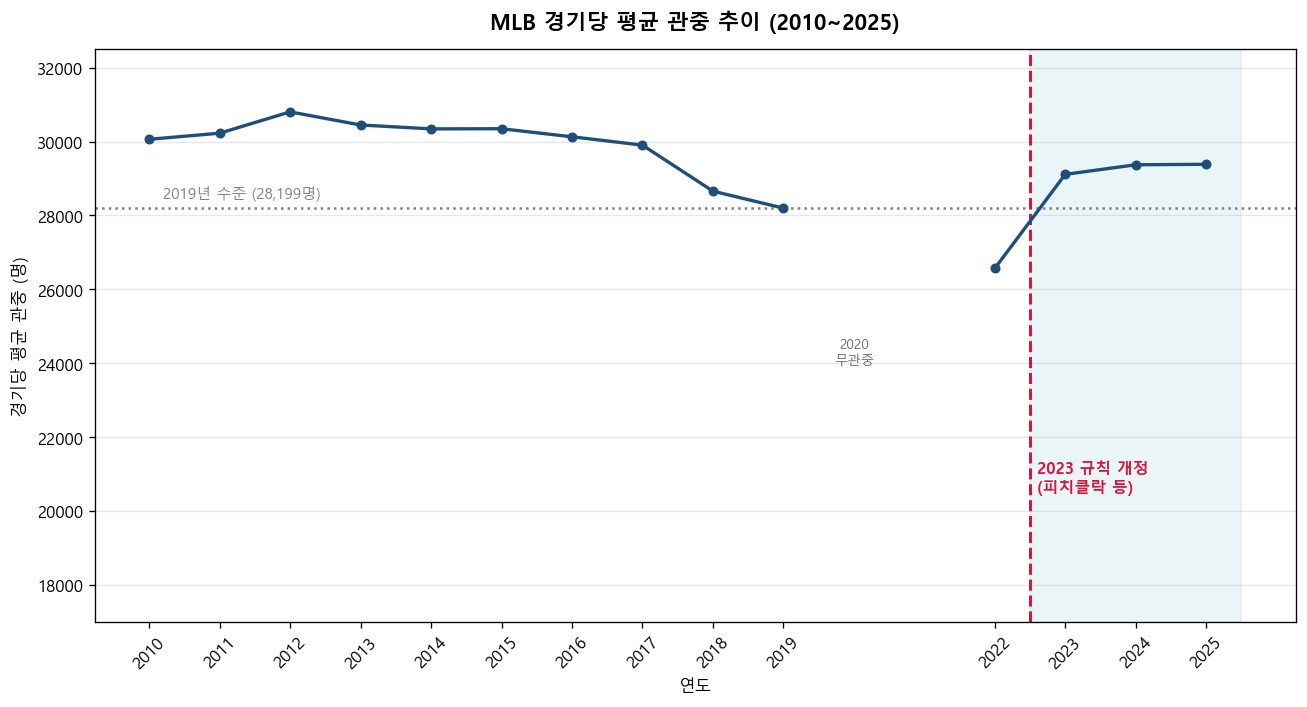

In [8]:
plot_df = summary.drop(index=[2020, 2021])
years = plot_df.index
vals = plot_df['경기당관중']

fig, ax = plt.subplots(figsize=(11, 6))

# 개입 후 구간
ax.axvspan(2022.5, 2025.5, color='lightblue', alpha=0.25, zorder=0)

# 2019년 기준 
ax.axhline(28199, color='gray', linestyle=':', linewidth=1.5, zorder=1)
ax.text(2010.2, 28199 + 300, '2019년 수준 (28,199명)',
        fontsize=9, color='gray')

ax.plot(range(2010, 2026), vals.reindex(range(2010, 2026)), marker='o', markersize=5,
        color='#1f4e79', linewidth=2, zorder=3)

# 개입
ax.axvline(2022.5, color='crimson', linestyle='--', linewidth=1.8, zorder=2)
ax.text(2022.6, 20500, '2023 규칙 개정\n(피치클락 등)',
        fontsize=9.5, color='crimson', fontweight='bold')

# 2020년 공백
ax.text(2020, 24000, '2020\n무관중', ha='center',
        fontsize=8, color='dimgray')

ax.set_xlabel('연도')
ax.set_ylabel('경기당 평균 관중 (명)')
ax.set_title('MLB 경기당 평균 관중 추이 (2010~2025)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_ylim(17000, 32500)
ax.set_xticks(years)
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('output/fig1_league_trend.png', dpi=200, bbox_inches='tight')
plt.show()

In [9]:
# 같은 구단의 전후 차이를 계산한다. 해당 시즌 30개 전체 구단의 변화는 기술통계다.
# p값과 신뢰구간은 구단별 차이의 독립성 등 확률모형 가정에 조건부다.
# 팀내 대응은 팀간 독립성을 보장하지 않으며, 공통 리그 충격은 남아 있다.
# 비모수검정도 독립성 문제를 해결하지 않는다. 관측 변화와 정책 인과효과를 구분한다.
def paired_test(y0, y1, label):
    paired = (teams[teams['yearID'].isin([y0, y1])]
              .pivot(index='franchID', columns='yearID', values='att_per_game')
              .dropna())
    delta = paired[y1] - paired[y0]
    n = len(delta)
    mean = float(delta.mean())
    sem = float(stats.sem(delta))
    ci_low, ci_high = stats.t.interval(0.95, df=n-1, loc=mean, scale=sem)
    _, normality_p = stats.shapiro(delta)
    t, pv = stats.ttest_rel(paired[y1], paired[y0])
    _, wil_p = stats.wilcoxon(paired[y1], paired[y0])
    dz = mean / delta.std(ddof=1)
    increased = int((delta > 0).sum())
    print(f'[{label}] n = {n}')
    print(f'  구단별 차이 평균: {mean:+,.0f}명/경기')
    print(f'  조건부 95% 신뢰구간: [{ci_low:+,.0f}, {ci_high:+,.0f}]명/경기')
    print(f'  증가 구단: {increased} / {n}')
    print(f'  Shapiro-Wilk: p = {normality_p:.4f} (정규성을 입증하는 검정은 아님)')
    print(f'  대응표본 t: t = {t:.3f}, p = {pv:.6f}')
    print(f'  Wilcoxon: p = {wil_p:.6f}')
    print(f"  Cohen's dz: {dz:.3f}\n")
    return {'baseline_year': y0, 'target_year': y1, 'n': n, 'increased': increased,
            'mean': mean, 'ci95_low': float(ci_low), 'ci95_high': float(ci_high),
            't': float(t), 'p': float(pv), 'd': float(dz)}

print('해석: 증가 구단 수·평균 차이는 관측 사실, p값·CI는 구단간 독립성 등 가정에 조건부인 보조 결과입니다.')
r19 = paired_test(2019, 2023, '2019 vs 2023')
r22 = paired_test(2022, 2023, '2022 vs 2023')
r25 = paired_test(2022, 2025, '2022 vs 2025')


해석: 증가 구단 수·평균 차이는 관측 사실, p값·CI는 구단간 독립성 등 가정에 조건부인 보조 결과입니다.
[2019 vs 2023] n = 30
  구단별 차이 평균: +918명/경기
  조건부 95% 신뢰구간: [-1,185, +3,022]명/경기
  증가 구단: 15 / 30
  Shapiro-Wilk: p = 0.2389 (정규성을 입증하는 검정은 아님)
  대응표본 t: t = 0.893, p = 0.379180
  Wilcoxon: p = 0.655438
  Cohen's dz: 0.163

[2022 vs 2023] n = 30
  구단별 차이 평균: +2,551명/경기
  조건부 95% 신뢰구간: [+1,390, +3,713]명/경기
  증가 구단: 26 / 30
  Shapiro-Wilk: p = 0.7557 (정규성을 입증하는 검정은 아님)
  대응표본 t: t = 4.493, p = 0.000103
  Wilcoxon: p = 0.000044
  Cohen's dz: 0.820

[2022 vs 2025] n = 30
  구단별 차이 평균: +2,824명/경기
  조건부 95% 신뢰구간: [+766, +4,882]명/경기
  증가 구단: 22 / 30
  Shapiro-Wilk: p = 0.3987 (정규성을 입증하는 검정은 아님)
  대응표본 t: t = 2.807, p = 0.008850
  Wilcoxon: p = 0.003223
  Cohen's dz: 0.512



In [10]:
piv = (teams[teams['yearID'].isin([2019, 2023])]
       .pivot(index='franchID', columns='yearID', values='att_per_game')
       .dropna())

piv['증가분'] = piv[2023] - piv[2019]
piv['증가율 (%)'] = piv['증가분'] / piv[2019] * 100
piv = piv.sort_values(by='증가율 (%)')

piv[piv['증가율 (%)'] <= 0]

Out[10]: 
yearID            2019          2023           증가분    증가율 (%)
franchID                                                     
OAK       20521.123457  10275.950617 -10245.172840 -49.925010
WSN       27898.530864  23034.962963  -4863.567901 -17.433061
MIN       28322.864198  24371.901235  -3950.962963 -13.949730
COL       36953.629630  32196.728395  -4756.901235 -12.872622
MIL       36090.530864  31498.111111  -4592.419753 -12.724722
ANA       37271.753086  32599.691358  -4672.061728 -12.535127
KCR       18267.395062  16136.444444  -2130.950617 -11.665323
CHC       38208.209877  34261.098765  -3947.111111 -10.330531
BOS       36106.506173  32989.259259  -3117.246914  -8.633477
ARI       26364.320988  24212.123457  -2152.197531  -8.163296
SFG       33429.135802  30866.086420  -2563.049383  -7.667112
STL       42967.814815  40013.469136  -2954.345679  -6.875718
LAD       49065.543210  47371.345679  -1694.197531  -3.452927
NYY       40795.111111  40358.222222   -436.888889  -1.07093

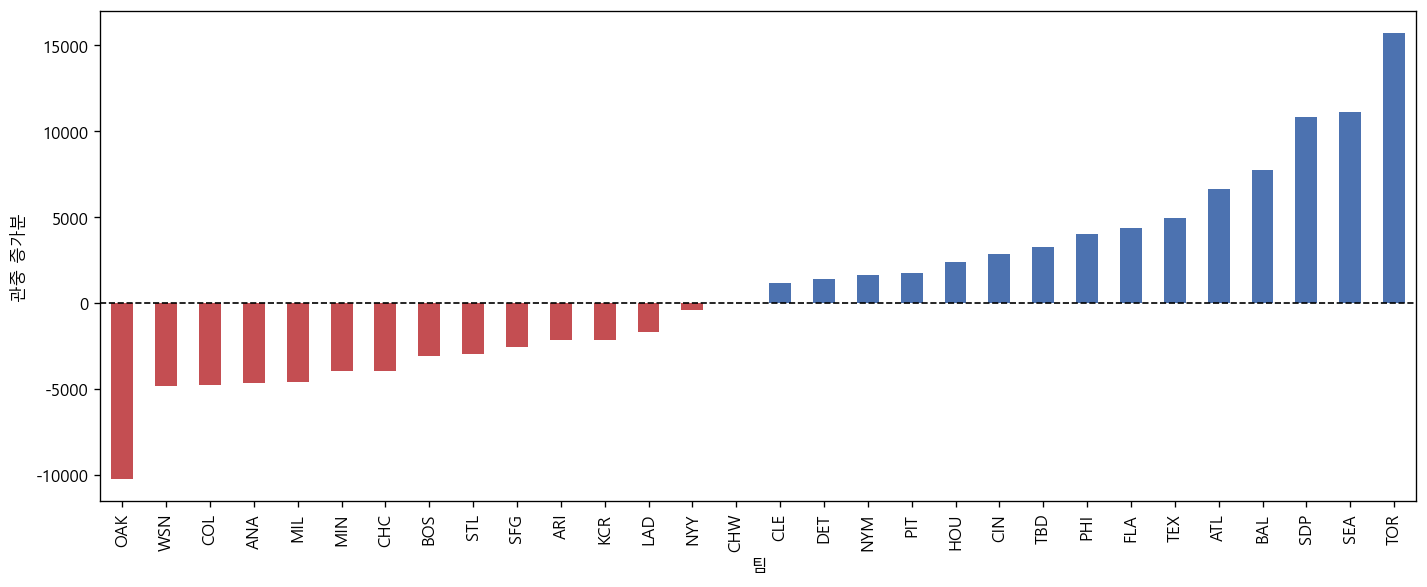

In [11]:
diff = piv['증가분'].sort_values()

# 음수=빨강, 양수=파랑
colors = ['#c44e52' if v < 0 else '#4c72b0' for v in diff]

diff.plot.bar(figsize=(12, 5), color=colors)

plt.axhline(0, linestyle='--', color='black', linewidth=1)
plt.ylabel('관중 증가분')
plt.xlabel('팀')
plt.tight_layout()
plt.show()

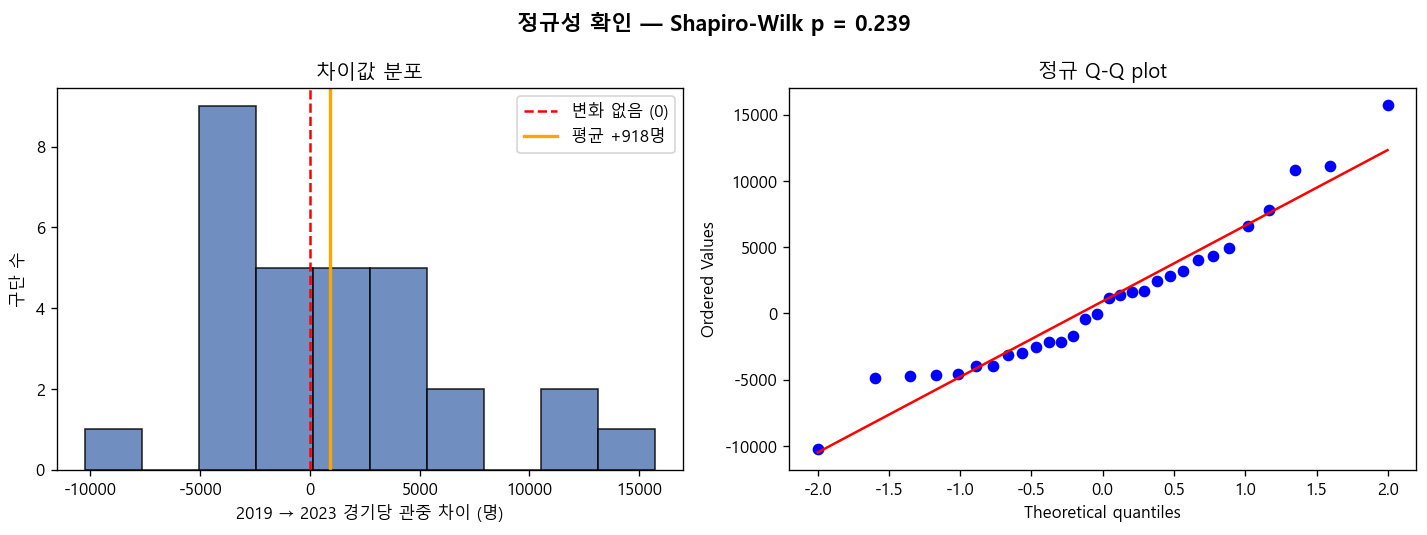

In [12]:
p = (teams[teams['yearID'].isin([2019, 2023])]
     .pivot(index='franchID', columns='yearID', values='att_per_game')
     .dropna())
d = p[2023] - p[2019]          # 음수 포함 30개

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 히스토그램
axes[0].hist(d, bins=10, color='#4c72b0', edgecolor='black', alpha=0.8)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5, label='변화 없음 (0)')
axes[0].axvline(d.mean(), color='orange', linewidth=2,
                label=f'평균 {d.mean():+,.0f}명')
axes[0].set_xlabel('2019 → 2023 경기당 관중 차이 (명)')
axes[0].set_ylabel('구단 수')
axes[0].set_title('차이값 분포')
axes[0].legend()

# QQ 플롯
stats.probplot(d, dist='norm', plot=axes[1])
axes[1].set_title('정규 Q-Q plot')

_, sp = stats.shapiro(d)
plt.suptitle(f'정규성 확인 — Shapiro-Wilk p = {sp:.3f}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('output/fig_normality.png', dpi=200, bbox_inches='tight')
plt.show()

In [13]:
# 30개 구단 전체의 증가 분포를 기술한다. 부호검정 역시 구단간 독립성을 가정하는 보조 결과다.
# 각 기준연도에서 2023년까지의 구단별 변화량에 같은 규칙을 적용한다.
# 증가 구단 비율의 양측 부호검정은 변화량이 0인 구단을 분모에서 제외한다.
# 극단값 제외 후 평균 검정은 표본 선택에 민감한지 살피는 보조 분석이다.
per_game = teams.pivot(index='franchID', columns='yearID', values='att_per_game')
for start in [2019, 2022]:
    delta = (per_game[2023] - per_game[start]).dropna()
    increased = int((delta > 0).sum())
    nonzero = int((delta != 0).sum())
    sign = stats.binomtest(increased, nonzero, p=0.5, alternative='two-sided')
    q1, q3 = delta.quantile([0.25, 0.75])
    iqr = q3 - q1
    keep = delta.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    trimmed = delta[keep]
    retest = stats.ttest_1samp(trimmed, popmean=0)
    print(f'{start}→2023  증가 {increased}/{len(delta)}, 중앙값 {delta.median():+,.1f}명, 부호검정 p={sign.pvalue:.6f}')
    print(f'  1.5×IQR 경계 [{q1-1.5*iqr:,.1f}, {q3+1.5*iqr:,.1f}]명')
    print('  제외한 franchID', ', '.join(delta[~keep].index) or '없음')
    print(f'  남은 {len(trimmed)}개 중 증가 {(trimmed > 0).sum()}개, 평균 {trimmed.mean():+,.1f}명, t={retest.statistic:.3f}, p={retest.pvalue:.6f}')

2019→2023  증가 15/30, 중앙값 +584.3명, 부호검정 p=1.000000
  1.5×IQR 경계 [-13,418.7, 14,160.4]명
  제외한 franchID TOR
  남은 29개 중 증가 14개, 평균 +408.7명, t=0.442, p=0.661845
2022→2023  증가 26/30, 중앙값 +2,045.5명, 부호검정 p=0.000059
  1.5×IQR 경계 [-5,847.6, 10,755.8]명
  제외한 franchID 없음
  남은 30개 중 증가 26개, 평균 +2,551.5명, t=4.493, p=0.000103


In [14]:
league = (summary.reset_index()[['yearID', '경기당관중']]
          .rename(columns={'경기당관중': 'att_pg'}))
# 2020 무관중, 2021 제한관중 (관중 수가 팬의 선택이 아니었던 해)
league = league[~league['yearID'].isin([2020, 2021])].copy()
 
league['time'] = league['yearID'] - 2010         
league['post'] = (league['yearID'] >= 2023).astype(int)
 
print(league[['yearID', 'att_pg', 'time', 'post']].round(0).to_string(index=False))

 
model = smf.ols('att_pg ~ time + post', data=league).fit()
 
print('\n=== 회귀 결과 ===')
print(pd.DataFrame({'coef': model.params.round(1),
                    'p': model.pvalues.round(4)}).to_string())
 
b0 = model.params['Intercept']
b1 = model.params['time']
b2 = model.params['post']
ci = model.conf_int().loc['post']
 
print(f'\nR² = {model.rsquared:.3f}')
print(f'회귀식: y = {b0:,.0f} - {abs(b1):.1f}×time + {b2:,.0f}×post')
print(f'\n공통 기울기 : 연 {b1:+.1f}명  (p={model.pvalues["time"]:.4f})')
print(f'개정 전후 수준 차이 : {b2:+,.0f}명  (p={model.pvalues["post"]:.4f})')
print(f'95% 신뢰구간 : [{ci[0]:,.0f}, {ci[1]:,.0f}]')

 yearID  att_pg  time  post
   2010 30063.0     0     0
   2011 30229.0     1     0
   2012 30806.0     2     0
   2013 30451.0     3     0
   2014 30346.0     4     0
   2015 30350.0     5     0
   2016 30131.0     6     0
   2017 29906.0     7     0
   2018 28660.0     8     0
   2019 28199.0     9     0
   2022 26567.0    12     0
   2023 29114.0    13     1
   2024 29374.0    14     1
   2025 29387.0    15     1

=== 회귀 결과 ===
              coef       p
Intercept  31105.9  0.0000
time        -288.7  0.0004
post        2227.9  0.0073

R² = 0.695
회귀식: y = 31,106 - 288.7×time + 2,228×post

공통 기울기 : 연 -288.7명  (p=0.0004)
개정 전후 수준 차이 : +2,228명  (p=0.0073)
95% 신뢰구간 : [735, 3,721]


In [15]:
# 제외한 2020·2021년은 관측 행에 없다. 시차 1은 남은 자료에서 이웃한 관측값이다.
print(f'분석한 시즌 {int(model.nobs)}개, 개정 후 {league.post.sum()}개')
print(f'Durbin–Watson {durbin_watson(model.resid):.4f}')
hac = model.get_robustcov_results(cov_type='HAC', maxlags=1, kernel='bartlett',
                                 use_correction=False, use_t=False)
i = model.model.exog_names.index('post')
print(f'일반 OLS: post {model.params["post"]:+,.1f}명, p={model.pvalues["post"]:.6f}')
print(f'HAC: post {hac.params[i]:+,.1f}명, 표준오차 {hac.bse[i]:,.1f}, p={hac.pvalues[i]:.6f}')
pred = model.predict(pd.DataFrame({'time': [13, 13], 'post': [0, 1]}))
print(f'2023년 모형 적합값: post=0 {pred.iloc[0]:,.0f}명, post=1 {pred.iloc[1]:,.0f}명')

분석한 시즌 14개, 개정 후 3개
Durbin–Watson 0.6673
일반 OLS: post +2,227.9명, p=0.007266
HAC: post +2,227.9명, 표준오차 712.8, p=0.001775
2023년 모형 적합값: post=0 27,352명, post=1 29,580명


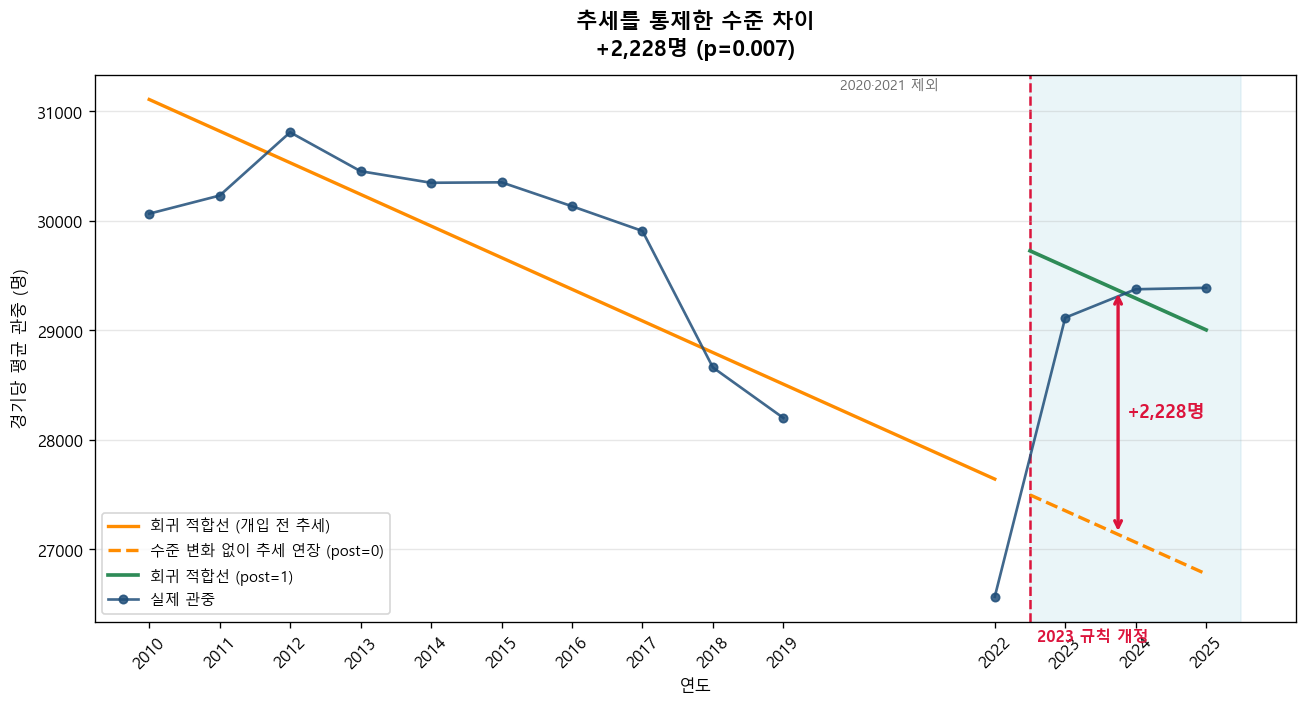

In [16]:
def yhat(year, post):
    return b0 + b1 * (year - 2010) + b2 * post
 
y_end = int(league['yearID'].max())
 
fig, ax = plt.subplots(figsize=(11, 6))
ax.axvspan(2022.5, y_end + 0.5, color='lightblue', alpha=0.25, zorder=0)
 
# 개입 전 적합선 (실선) 
ax.plot([2010, 2022], [yhat(2010, 0), yhat(2022, 0)],
        color='darkorange', linewidth=2,
        label='회귀 적합선 (개입 전 추세)', zorder=2)
 
# 개입 후: 추세 연장선(점선)과 적합선(실선)
ax.plot([2022.5, y_end], [yhat(2022.5, 0), yhat(y_end, 0)],
        color='darkorange', linewidth=2, linestyle='--',
        label='수준 변화 없이 추세 연장 (post=0)', zorder=2)
ax.plot([2022.5, y_end], [yhat(2022.5, 1), yhat(y_end, 1)],
        color='seagreen', linewidth=2.2,
        label='회귀 적합선 (post=1)', zorder=2)
 
# 실제 관측값
ax.plot(range(2010, 2026), league.set_index('yearID')['att_pg'].reindex(range(2010, 2026)), marker='o', markersize=5,
        color='#1f4e79', linewidth=1.6, alpha=0.85,
        label='실제 관중', zorder=3)
 
# 두 회귀선의 간격 = post 계수
mid = (2022.5 + y_end) / 2
ax.annotate('', xy=(mid, yhat(mid, 1)), xytext=(mid, yhat(mid, 0)),
            arrowprops=dict(arrowstyle='<->', color='crimson', lw=2))
ax.text(mid + 0.12, (yhat(mid, 1) + yhat(mid, 0)) / 2,
        f'+{b2:,.0f}명', color='crimson', fontsize=11,
        fontweight='bold', va='center')
 
ax.axvline(2022.5, color='crimson', linestyle='--', linewidth=1.5, zorder=1)
ax.text(2022.6, league['att_pg'].min() - 400, '2023 규칙 개정',
        fontsize=9.5, color='crimson', fontweight='bold')
ax.text(2020.5, league['att_pg'].max() + 400, '2020·2021 제외',
        ha='center', fontsize=8.5, color='dimgray')
 
ax.set_xlabel('연도')
ax.set_ylabel('경기당 평균 관중 (명)')
ax.set_title(f'추세를 통제한 수준 차이\n'
             f'+{b2:,.0f}명 (p={model.pvalues["post"]:.3f})',
             fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(league['yearID'].tolist())
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='lower left', fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('output/fig2_regression.png', dpi=200, bbox_inches='tight')
plt.show()

In [17]:
league['time'] = league['yearID'] - 2010      # 0, 1, 2, ... 15
league['post'] = (league['yearID'] >= 2023).astype(int)   # 0 또는 1
league['time_post'] = league['post'] * (league['yearID'] - 2022)

print(league[['yearID', 'att_pg', 'time', 'post', 'time_post']].to_string(index=False))
print('→ 2022년 time=12 확인 (10이면 시간 간격 왜곡)\n')

# ── 후기간 3점에 따른 수준·기울기 추정의 불확실성 ──
corr = league['post'].corr(league['time_post'])
print(f'post ↔ time_post 상관: {corr:.3f}')
print(f'개입 후 관측치: {league["post"].sum()}개')
print('개정 후 3개 관측으로 수준과 기울기를 정밀하게 구분하기 어렵다. 높은 변수 상관만으로 추정 불가능을 뜻하지는 않는다.')

# ── 모형 4개 비교 ──────────────────────────────────
m0 = smf.ols('att_pg ~ post', data=league).fit()              # 추세 미통제
m1 = smf.ols('att_pg ~ time + post + time_post', data=league).fit()
m2 = smf.ols('att_pg ~ time + post', data=league).fit()       # 채택
m3 = smf.ols('att_pg ~ time + post',
             data=league[league['yearID'] != 2022]).fit()     # 민감도

compare = pd.DataFrame({
    '모형': ['⓪ post만 (추세 미통제)', '① time+post+time_post',
           '② time+post (채택)', '③ 2022 제외'],
    'post 기준점': ['전후 평균차', '2022년 절편차 (2023년: post+time_post)',
                  '모든 후기간의 공통 수준차', '2022년 제외 후 공통 수준차'],
    'post 계수': [m0.params['post'], m1.params['post'],
                m2.params['post'], m3.params['post']],
    'p값': [m0.pvalues['post'], m1.pvalues['post'],
           m2.pvalues['post'], m3.pvalues['post']],
    'R²': [m0.rsquared, m1.rsquared, m2.rsquared, m3.rsquared],
    'AIC': [m0.aic, m1.aic, m2.aic, m3.aic],
})
print(compare.round(3).to_string(index=False))
print(pd.DataFrame({'기울기 변화 허용 모형 계수': m1.params, 'p값': m1.pvalues}).round(4))
print(f'2022년 제외 시 수준 차이 {m3.params["post"]:+,.2f}명, p={m3.pvalues["post"]:.6f}')
# time_post의 기준이 2022년이므로 2023년 적합선 간격은 두 계수의 합이다.
# 표의 p값은 각 모형 post 계수 검정이며 동일한 2023년 대비량의 검정이 아니다.
contrast_2023 = m1.t_test('post + time_post = 0')
print(f'기울기 변화 모형의 2023년 적합선 간격: {float(contrast_2023.effect.item()):+,.2f}명')
print('모형 선택: 후기간의 정보 부족과 간결성을 고려해 공통 기울기 모형을 주 분석으로 삼고 대안 결과를 함께 보고한다.')
print('AIC는 동일 표본 모형끼리만 비교한다. 2022년 제외 모형의 AIC는 직접 비교하지 않는다.')


 yearID    att_pg  time  post  time_post
   2010 30063.295     0     0          0
   2011 30228.764     1     0          0
   2012 30806.283     2     0          0
   2013 30451.211     3     0          0
   2014 30345.523     4     0          0
   2015 30349.662     5     0          0
   2016 30131.402     6     0          0
   2017 29905.525     7     0          0
   2018 28659.511     8     0          0
   2019 28198.792     9     0          0
   2022 26566.526    12     0          0
   2023 29114.142    13     1          1
   2024 29373.571    14     1          2
   2025 29386.593    15     1          3
→ 2022년 time=12 확인 (10이면 시간 간격 왜곡)

post ↔ time_post 상관: 0.908
개입 후 관측치: 3개
개정 후 3개 관측으로 수준과 기울기를 정밀하게 구분하기 어렵다. 높은 변수 상관만으로 추정 불가능을 뜻하지는 않는다.
                   모형                          post 기준점  post 계수    p값    R²     AIC
     ⓪ post만 (추세 미통제)                            전후 평균차 -318.246 0.683 0.014 239.345
① time+post+time_post 2022년 절편차 (2023년: post+time_post) 1421.336 0.242 0

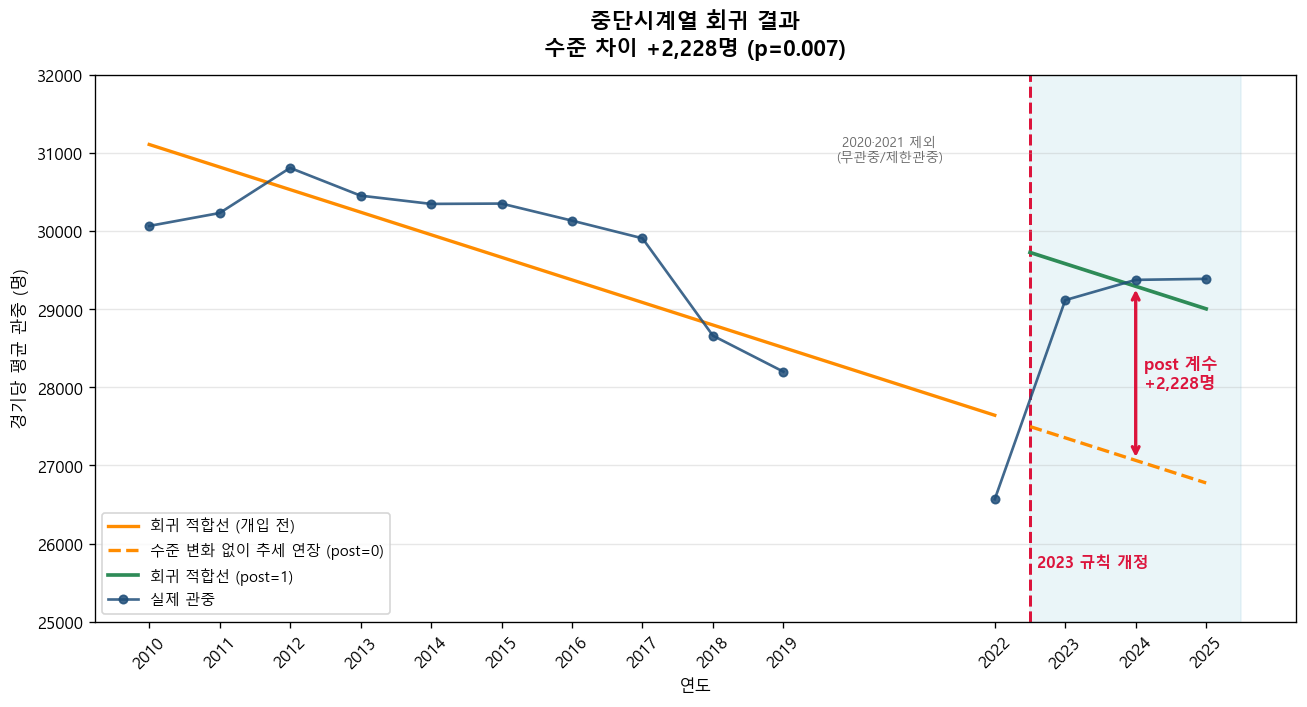

In [18]:
# ── 회귀선 두 개: post=0 과 post=1 ─────────────────
b0 = m2.params['Intercept']
b1 = m2.params['time']
b2 = m2.params['post']

def yhat(year, post):
    return b0 + b1 * (year - 2010) + b2 * post

fig, ax = plt.subplots(figsize=(11, 6))

ax.axvspan(2022.5, 2025.5, color='lightblue', alpha=0.25, zorder=0)

# ① 개입 전 구간 — 적합선 (실선)
x_pre = [2010, 2022]
ax.plot(x_pre, [yhat(x, 0) for x in x_pre],
        color='darkorange', linewidth=2, zorder=2,
        label='회귀 적합선 (개입 전)')

# ② 개입 후 구간 — 반사실 (점선, post=0)
x_post = [2022.5, 2025]
ax.plot(x_post, [yhat(x, 0) for x in x_post],
        color='darkorange', linewidth=2, linestyle='--', zorder=2,
        label='수준 변화 없이 추세 연장 (post=0)')

# ③ 개입 후 구간 — 적합선 (실선, post=1)
ax.plot(x_post, [yhat(x, 1) for x in x_post],
        color='seagreen', linewidth=2.2, zorder=2,
        label=f'회귀 적합선 (post=1)')

# ④ 실제 관측값
ax.plot(range(2010, 2026), league.set_index('yearID')['att_pg'].reindex(range(2010, 2026)), marker='o', markersize=5,
        color='#1f4e79', linewidth=1.6, alpha=0.85,
        label='실제 관중', zorder=3)

# ⑤ 두 회귀선의 간격 = post 계수
mid = 2024
ax.annotate('', xy=(mid, yhat(mid, 1)), xytext=(mid, yhat(mid, 0)),
            arrowprops=dict(arrowstyle='<->', color='crimson', lw=2))
ax.text(mid + 0.12, (yhat(mid, 1) + yhat(mid, 0)) / 2,
        f'post 계수\n+{b2:,.0f}명', color='crimson',
        fontsize=10, fontweight='bold', va='center')

ax.axvline(2022.5, color='crimson', linestyle='--', linewidth=1.8, zorder=1)
ax.text(2022.6, 25700, '2023 규칙 개정', fontsize=9.5,
        color='crimson', fontweight='bold')

ax.text(2020.5, 30900, '2020·2021 제외\n(무관중/제한관중)',
        ha='center', fontsize=8, color='dimgray')

ax.set_xlabel('연도')
ax.set_ylabel('경기당 평균 관중 (명)')
ax.set_title(f'중단시계열 회귀 결과\n'
             f'수준 차이 +{b2:,.0f}명 (p={m2.pvalues["post"]:.3f})',
             fontsize=13, fontweight='bold', pad=12)
ax.set_ylim(25000, 32000)
ax.set_xticks(league['yearID'].tolist())
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='lower left', fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('output/fig_its.png', dpi=200, bbox_inches='tight')
plt.show()

In [19]:
# 재사용 가능한 보고 산출물: 원자료 해시와 생성 시각을 함께 기록한다.
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version

export_dir = Path('generated')
export_dir.mkdir(exist_ok=True)
generated_at = datetime.now(timezone.utc).isoformat(timespec='seconds')
league_export = summary.reset_index().rename(columns={
    'yearID': 'year', '팀수': 'n_teams', '총관중': 'total_attendance',
    '총홈경기': 'total_home_games', '경기당관중': 'attendance_per_game'})
league_export['attendance_per_game'] = league_export.total_attendance / league_export.total_home_games
league_export['excluded_from_trend'] = league_export.year.isin([2020, 2021])
league_export['source_sha256'] = source_sha256
league_export['generated_at_utc'] = generated_at
league_export.to_csv(export_dir / 'league_summary.csv', index=False, encoding='utf-8-sig')

wide = teams.pivot(index='franchID', columns='yearID', values='att_per_game')
review = wide[[2019, 2022, 2023]].rename(columns=lambda y: f'attendance_per_game_{y}').copy()
names = teams.loc[teams.yearID == 2023].set_index('franchID')['name']
review.insert(0, 'team_name_2023_source', names)
for y in [2019, 2022]:
    review[f'change_pct_vs_{y}'] = (review.attendance_per_game_2023 / review[f'attendance_per_game_{y}'] - 1) * 100
review['below_2019'] = review.attendance_per_game_2023 < review.attendance_per_game_2019
review = review.sort_values('change_pct_vs_2019').reset_index()
review['source_sha256'] = source_sha256
review['generated_at_utc'] = generated_at
review.to_csv(export_dir / 'team_review.csv', index=False, encoding='utf-8-sig')

comparisons = []
for r in [r19, r22, r25]:
    y0, y1 = r['baseline_year'], r['target_year']
    baseline = float(league_export.set_index('year').loc[y0, 'attendance_per_game'])
    target = float(league_export.set_index('year').loc[y1, 'attendance_per_game'])
    comparisons.append({'baseline_year': y0, 'target_year': y1, 'n_teams': r['n'],
        'increased_teams': r['increased'], 'mean_difference': r['mean'],
        'ci95_low': r['ci95_low'], 'ci95_high': r['ci95_high'], 'p_value': r['p'],
        'league_baseline': baseline, 'league_target': target,
        'league_change_pct': (target / baseline - 1) * 100})
def model_summary(fit):
    bounds = fit.conf_int().loc['post']
    return {'level_difference': float(fit.params['post']), 'p_value': float(fit.pvalues['post']),
            'ci95_low': float(bounds.iloc[0]), 'ci95_high': float(bounds.iloc[1])}
payload = {'schema_version': 1, 'generated_at_utc': generated_at,
    'source': {'name': 'Lahman Teams.csv (2025, commit-pinned mirror)', 'url': csv_url, 'sha256': source_sha256},
    'analysis': {'start_year': 2010, 'end_year': 2025, 'n_team_seasons': int(len(teams)),
                 'excluded_trend_years': [2020, 2021], 'target_report_year': 2023},
    'inference_note': '30개 전체 구단의 관측 변화와 확률모형 기반 추론을 구분한다. p값·CI는 구단간 독립성 등 가정에 조건부이며 정책의 인과효과가 아니다.',
    'comparisons': comparisons,
    'models': {'primary': model_summary(m2), 'without_2022': model_summary(m3)},
    'environment': {'python': platform.python_version(), 'platform': platform.system(),
        'packages': {p: version(p) for p in ['numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib', 'nbformat', 'nbclient', 'ipykernel']}}}
(export_dir / 'summary.json').write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8')
assert len(review) == 30 and review.franchID.is_unique
assert int(review.below_2019.sum()) == 15
assert [x['increased_teams'] for x in comparisons] == [15, 26, 22]
print('내보내기 완료:', ', '.join(p.name for p in export_dir.glob('*') if p.is_file()))
print('구단 검토표 30행 / 리그 집계 16행 / 세 시즌 비교 / 입력 해시 일치 검증 통과')
print('생성 시각 (UTC):', generated_at)


내보내기 완료: league_summary.csv, summary.json, team_review.csv
구단 검토표 30행 / 리그 집계 16행 / 세 시즌 비교 / 입력 해시 일치 검증 통과
생성 시각 (UTC): 2026-11-17T08:57:31+00:00
